# Step 1c: the Fermi–Dirac integral, paper Fig. 1(b) and our TCAD check
Panel (a): paper Fig. 1(b) rebuilt with fermi.py [P, Eqs. (1)–(2)].
Panel (b): Device 1 TCAD at equilibrium, n against η_F along a cut at Y = 3.5 µm [TCAD, our addition].

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from fermi import fermi_half_numerical, fermi_half_paper

In [5]:
# TCAD cut: Device 1 equilibrium (n2_Equi_des.tdr), Y = 3.5 um, made by tcad_scripts/cut_n2.tcl [TCAD]
data = np.genfromtxt("tcad_data/device1_n2_equilibrium_cut_y3.5um.csv", delimiter=",", skip_header=2)
X, n, Ec, phi_n, xAl = data.T            # um, cm^-3, eV, V, Al fraction

kT = 8.617333e-5 * 300.0                  # thermal energy at 300 K, in eV
EF = -phi_n                               # Fermi level in eV (Sentaurus: E_F = -q * phi_n)
eta_F = (EF - Ec) / kT                    # the variable of Eq. (1), from the TCAD bands
semi = n > 0                              # semiconductor points only (n = 0 in SiN, gas, substrate)
depth_nm = (X + 1.12) * 1000.0            # depth below the grade top, in nm

i = np.argmax(n)
print(f"3DEG peak: n = {n[i]:.3e} cm^-3 at depth {depth_nm[i]:.1f} nm, x_Al = {xAl[i]:.3f}, eta_F = {eta_F[i]:+.2f}")

gan = semi & (xAl == 0)
NC_gan = n[gan] / np.array([fermi_half_numerical(e) for e in eta_F[gan]])
print(f"TCAD N_C in the GaN: {np.median(NC_gan):.3e} cm^-3")

3DEG peak: n = 9.663e+18 cm^-3 at depth 15.0 nm, x_Al = 0.101, eta_F = +2.57
TCAD N_C in the GaN: 2.244e+18 cm^-3


In [6]:
# Paper Fig. 1(b), read from the PDF's vector paths [P]
paper = {}
for name in ["numerical_markers", "analytical_line", "first_derivative_line", "second_derivative_line"]:
    paper[name] = np.loadtxt(f"paper_data/fig1b_{name}.csv", delimiter=",", skiprows=3)
NC_paper = 9.50e16   # cm^-3, read from Fig. 1(b) [P]; the paper does not state m*

In [7]:
eta = np.linspace(-11, 11, 2201)          # a bit wider than the plot, so the derivative ends stay clean
n_formula = NC_paper * fermi_half_paper(eta)            # Eq. (2), with the 2/sqrt(pi) put back
dn = np.gradient(n_formula, eta)                         # first derivative, dn/d(eta_F)
d2n = np.gradient(dn, eta)                               # second derivative
eta_pts = np.linspace(-10, 10, 34)                       # 34 points, like the paper's circles
n_exact = NC_paper * np.array([fermi_half_numerical(e) for e in eta_pts])   # Eq. (1), exact

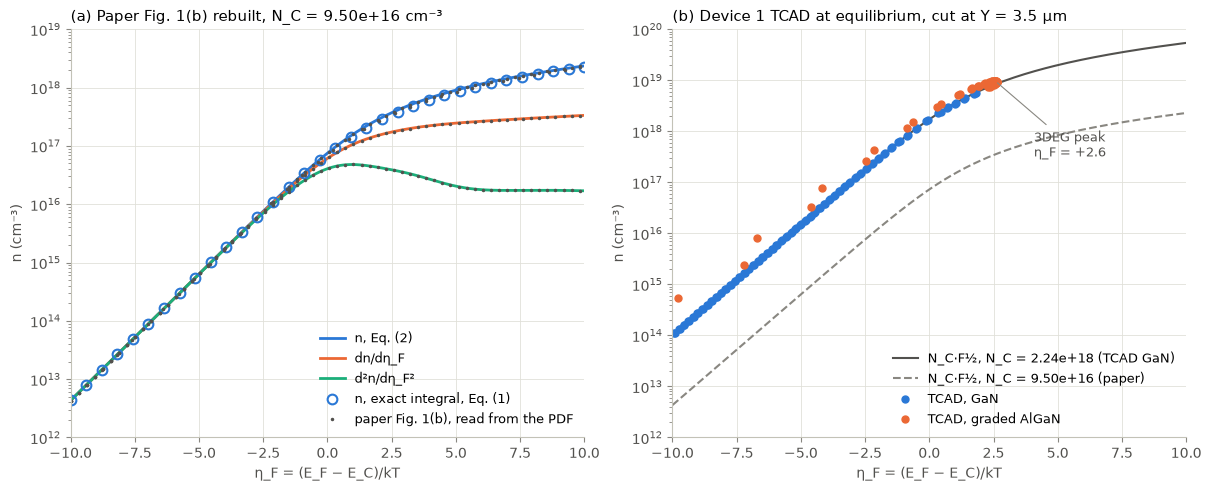

In [8]:
import os
os.makedirs("figures", exist_ok=True)

BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

# (a) paper Fig. 1(b) rebuilt with our code, paper points on top
ax1.semilogy(eta, n_formula, color=BLUE, lw=2, label="n, Eq. (2)")
ax1.semilogy(eta, dn, color=ORANGE, lw=2, label="dn/dη_F")
ax1.semilogy(eta, d2n, color=AQUA, lw=2, label="d²n/dη_F²")
ax1.semilogy(eta_pts, n_exact, "o", mfc="none", mec=BLUE, ms=7, mew=1.5, label="n, exact integral, Eq. (1)")
for k in ["analytical_line", "first_derivative_line", "second_derivative_line"]:
    ax1.semilogy(paper[k][::6, 0], paper[k][::6, 1], ".", color=INK, ms=3)
ax1.semilogy(paper["numerical_markers"][:, 0], paper["numerical_markers"][:, 1], ".", color=INK, ms=3,
             label="paper Fig. 1(b), read from the PDF")
ax1.set_xlim(-10, 10); ax1.set_ylim(1e12, 1e19)
ax1.set_xlabel("η_F = (E_F − E_C)/kT"); ax1.set_ylabel("n (cm⁻³)")
ax1.set_title(f"(a) Paper Fig. 1(b) rebuilt, N_C = {NC_paper:.2e} cm⁻³", loc="left", fontsize=11)
ax1.grid(True, color=GRID, lw=0.6); ax1.legend(loc="lower right", fontsize=9)

# (b) our TCAD points on the same kind of curve
NC_t = np.median(NC_gan)
eta_line = np.linspace(-10, 10, 201)
F_line = np.array([fermi_half_numerical(e) for e in eta_line])
show = semi & (eta_F > -10) & (eta_F < 10)
ax2.semilogy(eta_line, NC_t * F_line, color=INK, lw=1.5, label=f"N_C·F½, N_C = {NC_t:.2e} (TCAD GaN)")
ax2.semilogy(eta_line, NC_paper * F_line, color=MUTED, lw=1.5, ls="--", label=f"N_C·F½, N_C = {NC_paper:.2e} (paper)")
ax2.semilogy(eta_F[show & (xAl == 0)], n[show & (xAl == 0)], "o", color=BLUE, ms=5, label="TCAD, GaN")
ax2.semilogy(eta_F[show & (xAl > 0)], n[show & (xAl > 0)], "o", color=ORANGE, ms=5, label="TCAD, graded AlGaN")
ax2.annotate(f"3DEG peak\nη_F = {eta_F[i]:+.1f}", (eta_F[i], n[i]), (eta_F[i] + 1.5, n[i] / 30),
             fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax2.set_xlim(-10, 10); ax2.set_ylim(1e12, 1e20)
ax2.set_xlabel("η_F = (E_F − E_C)/kT"); ax2.set_ylabel("n (cm⁻³)")
ax2.set_title("(b) Device 1 TCAD at equilibrium, cut at Y = 3.5 µm", loc="left", fontsize=11)
ax2.grid(True, color=GRID, lw=0.6); ax2.legend(loc="lower right", fontsize=9)

fig.savefig("figures/step1c_fig1b.png", dpi=200)
plt.show()